# BA clustering: so sánh phương pháp và phân tích độ nhạy tham số

Notebook dùng **code hiện có**, không đổi thuật toán: Standard Continuous BA (SSE),
K-Means nhiều lần khởi tạo, **OFAT** cho sáu tham số và **grid** cho cặp A0/r0.
Mỗi cấu hình dùng cùng dữ liệu chuẩn hóa và các seed ghép cặp.

**Cách dùng:** chọn kernel Python của `.venv`, sửa `DATASET_PATH` ở ô cấu hình,
chọn `N_CLUSTERS` và `LABEL_COLUMN` nếu có nhãn, sau đó Run All. Đường dẫn CSV có thể
là tuyệt đối hoặc tương đối từ project root. Không cần chuyển dữ liệu vào thư mục
cố định; `datasets/` là nơi thuận tiện để đặt dữ liệu.

Mặc định là dữ liệu mẫu nhỏ và seed kỹ thuật 0,1. Kết quả minh họa pipeline hoạt động,
không phải kết luận xác nhận độ nhạy hay bằng chứng BA vượt K-Means. Đồ thị trong file
đã chạy gắn với cấu hình in bên dưới; đổi dữ liệu thì cần chạy lại toàn bộ notebook.

Phiên kiểm tra lưu output bằng sequential Python runner, **chưa kiểm chứng kernel
Jupyter/VS Code** trong môi trường hiện tại. Không có output giả lập.

In [1]:
from pathlib import Path
from dataclasses import replace
from datetime import datetime, timezone
import json
import os
import uuid

import numpy as np
import pandas as pd
from PIL import Image
from matplotlib.figure import Figure

from ba_clustering import BAConfig, BatClustering, KMeansConfig, compute_sse, run_kmeans
from ba_clustering.bat_algorithm import velocity_update, position_update
from ba_clustering.experiments import (
    ExperimentSpec, expand_conditions, load_base_config, prepare_dataset, run_experiment,
)
from ba_clustering.results import load_runs, runs_table, read_manifest, environment_info
from ba_clustering.plots import generate_plots

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "configs/default.yaml").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Mở notebook từ ba-clustering/ hoặc notebooks/.")
print("Project:", PROJECT_ROOT)
print("Python/environment:", json.dumps(environment_info(), indent=2))

Project: /home/vxh/Desktop/New Folder/ba-clustering
Python/environment: {
  "ba_clustering": "0.1.0",
  "git_commit": null,
  "python": "3.12.13",
  "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.43",
  "numpy": "2.5.4",
  "scipy": "1.18.1",
  "scikit_learn": "1.9.1",
  "pandas": "3.1.1",
  "matplotlib": "3.11.2"
}


## 1. Cấu hình dữ liệu và ngân sách

CSV có dòng tên cột; tất cả cột đặc trưng phải là số hữu hạn. Nếu có cột lớp, đặt
`LABEL_COLUMN` để loại khỏi đặc trưng; nhãn chỉ dùng đánh giá ARI. Không tự điền NaN,
không tự đoán K, không tự đưa cột văn bản vào mô hình. Không đưa ID/nhãn số vào features.
Mặc định 12 bats, 24 iterations = **300 SSE evaluations/run**; 2 seed là minh họa.
Không dùng seed discovery/confirmation để debug. Có thể tăng lặp bằng roster pilot sau
khi ước lượng chi phí; chưa tự chạy nghiên cứu chính thức.

In [2]:
# Thay địa chỉ này bằng CSV của bạn; có thể dùng "/home/.../my_dataset.csv".
DATASET_PATH = os.environ.get("BA_NOTEBOOK_DATASET", "datasets/example_blobs.csv")
N_CLUSTERS = int(os.environ.get("BA_NOTEBOOK_CLUSTERS", "3"))
LABEL_COLUMN = os.environ.get("BA_NOTEBOOK_LABEL_COLUMN") or None
PREPROCESSING = "zscore"
SEEDS = (0, 1)  # kỹ thuật; không dùng 1000..1009 hay 2000..2019
POPULATION_SIZE = 12
MAX_ITERATIONS = 24
RUN_GRID = True

FACTORS = {
    "A0": (0.25, 0.5, 1.0), "r0": (0.1, 0.5, 0.9),
    "alpha": (0.7, 0.9, 1.0), "gamma": (0.1, 0.9, 2.0),
    "f_min": (0.0, 0.5, 1.0), "f_max": (0.5, 2.0, 5.0),
}
GRID_FACTORS = {"A0": FACTORS["A0"], "r0": FACTORS["r0"]}

path = Path(DATASET_PATH).expanduser()
if not path.is_absolute():
    path = PROJECT_ROOT / path
path = path.resolve(strict=True)
if path.suffix.lower() != ".csv":
    raise ValueError("Notebook hiện hỗ trợ CSV có header; xuất Excel sang CSV trước.")
if set(SEEDS) & (set(range(1000, 1010)) | set(range(2000, 2020))):
    raise ValueError("Không dùng seed formal trong notebook minh họa này.")
options = {"loader": "csv", "path": str(path), "n_clusters": N_CLUSTERS,
           "label_column": LABEL_COLUMN, "name": "custom"}
prepared = prepare_dataset(options, PREPROCESSING)
print("Dataset:", path)
print("Shape/K:", prepared.X.shape, N_CLUSTERS)
print("Processed data SHA256:", prepared.sha256)
print("Constant features:", prepared.preprocessing.constant_features)
display(pd.read_csv(path).head())
display(pd.DataFrame(prepared.X).describe())

Dataset: /home/vxh/Desktop/New Folder/ba-clustering/datasets/example_blobs.csv
Shape/K: (90, 2) 3
Processed data SHA256: 1011e46ca9a1f687ee07e0f4614a6ddc1bf5a11122e851f219ce30d91e3f8a07
Constant features: []


,feature_1,feature_2
0,6.148828,2.112832
1,-2.877709,9.859984
2,-6.671721,-6.254651
3,4.078236,1.711040
4,-7.869188,-7.936475


,0,1
count,9.000000e+01,9.000000e+01
mean,-7.401487e-18,-3.083953e-19
std,1.005602e+00,1.005602e+00
min,-1.331476e+00,-1.461099e+00
25%,-1.009807e+00,-1.198079e+00
50%,-2.456769e-01,9.695137e-02
75%,1.240172e+00,1.051584e+00
max,1.608417e+00,1.419758e+00


## 2. Kiểm tra số học trước khi chạy

Đây là kiểm tra giá trị đã biết, không phải so sánh hiệu năng. Nếu sai thì dừng.
Toy SSE phải lần lượt bằng 2, 1, 5; velocity phải bằng `[0.5, -0.5]`.

In [3]:
toy = np.array([[1.0], [2.0], [8.0], [9.0]])
toy_rows = []
for centroids, expected in [([[2.0], [8.0]], 2.0),
                            ([[1.5], [8.5]], 1.0),
                            ([[2.5], [7.5]], 5.0)]:
    actual = compute_sse(toy, centroids)
    assert actual == expected
    toy_rows.append({"centroids": str(centroids), "SSE": actual, "expected": expected})
v = velocity_update(np.zeros(2), np.array([2., 8.]), np.array([1.5, 8.5]), 1.)
np.testing.assert_array_equal(v, [0.5, -0.5])
np.testing.assert_array_equal(position_update(np.array([2., 8.]), v), [2.5, 7.5])
display(pd.DataFrame(toy_rows))
print("PASS: toy SSE, velocity và proposed position.")

,centroids,SSE,expected
0,"[[2.0], [8.0]]",2.0,2.0
1,"[[1.5], [8.5]]",1.0,1.0
2,"[[2.5], [7.5]]",5.0,5.0


PASS: toy SSE, velocity và proposed position.


## 3. Thiết kế so sánh

OFAT giữ các tham số khác ở reference, thay từng tham số qua ba mức. Grid giao nhau
A0/r0 để quan sát tương tác; các tham số khác giữ reference. Đây là **hai thiết kế phân
tích**, không phải hai thuật toán tối ưu khác. Mỗi thiết kế có BA reference và K-Means.
Các ô grid không chứng minh tương tác có ý nghĩa thống kê chỉ bằng màu heatmap.

In [4]:
base = load_base_config(PROJECT_ROOT / "configs/default.yaml")
ba_base = {**base["ba"], "population_size": POPULATION_SIZE,
           "max_iterations": MAX_ITERATIONS, "patience": None, "tolerance": 0.0}
spec = ExperimentSpec(
    experiment_id="ofat", description="Notebook engineering illustration; not formal research",
    design="ofat", datasets={"custom": options}, preprocessing_method=PREPROCESSING,
    seeds=SEEDS, algorithms=("ba", "kmeans"), ba_base=ba_base,
    kmeans=base["kmeans"], factors=FACTORS,
)
conditions = expand_conditions(spec)
print("BA reference:", ba_base)
print("OFAT BA conditions:", len(conditions))
print("OFAT records:", (len(conditions) + 1) * len(SEEDS))
print("OFAT SSE objective budget:", len(conditions) * len(SEEDS)
      * POPULATION_SIZE * (MAX_ITERATIONS + 1))
print("Grid enabled:", RUN_GRID, "; seeds:", SEEDS)
print("K-Means cost is Lloyd iterations, not BA objective evaluations.")

BA reference: {'population_size': 12, 'max_iterations': 24, 'A0': 0.5, 'r0': 0.5, 'alpha': 0.9, 'gamma': 0.9, 'f_min': 0.0, 'f_max': 2.0, 'tolerance': 0.0, 'patience': None}
OFAT BA conditions: 13
OFAT records: 28
OFAT SSE objective budget: 7800
Grid enabled: True ; seeds: (0, 1)
K-Means cost is Lloyd iterations, not BA objective evaluations.


In [5]:
# Tạo thư mục phiên mới mỗi lần chạy ô này; không resume/overwrite dữ liệu cũ.
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
output_root = Path(os.environ.get("BA_NOTEBOOK_OUTPUT_ROOT", str(PROJECT_ROOT / "results")))
SESSION_ROOT = output_root / ("notebook_" + stamp + "_" + uuid.uuid4().hex[:8])
SESSION_ROOT.mkdir(parents=True, exist_ok=False)
settings = {"purpose": "notebook_smoke_only", "dataset_path": str(path),
            "n_clusters": N_CLUSTERS, "label_column": LABEL_COLUMN,
            "preprocessing": PREPROCESSING, "seeds": list(SEEDS),
            "processed_data_sha256": prepared.sha256, "run_grid": RUN_GRID}
(SESSION_ROOT / "notebook_settings.json").write_text(json.dumps(settings, indent=2) + "\n")
ofat_outcome = run_experiment(spec, SESSION_ROOT)
assert ofat_outcome.n_failed == 0
ofat_records = load_runs(ofat_outcome.directory)
assert len(ofat_records) == (len(conditions) + 1) * len(SEEDS)
if RUN_GRID:
    grid_spec = replace(spec, experiment_id="grid", design="grid", factors=GRID_FACTORS)
    grid_outcome = run_experiment(grid_spec, SESSION_ROOT)
    assert grid_outcome.n_failed == 0
print("Output:", SESSION_ROOT)
print("OFAT:", ofat_outcome)
if RUN_GRID:
    print("Grid:", grid_outcome)
frame = runs_table(ofat_records)
display(frame[["algorithm", "condition_id", "seed", "sse", "silhouette",
               "runtime_seconds", "n_empty_clusters"]])

Output: /home/vxh/Desktop/New Folder/ba-clustering/results/notebook_20261105T105340Z_b4df6629
OFAT: ExperimentOutcome(directory=PosixPath('/home/vxh/Desktop/New Folder/ba-clustering/results/notebook_20261105T105340Z_b4df6629/ofat'), n_completed=28, n_failed=0, n_skipped=0)
Grid: ExperimentOutcome(directory=PosixPath('/home/vxh/Desktop/New Folder/ba-clustering/results/notebook_20261105T105340Z_b4df6629/grid'), n_completed=20, n_failed=0, n_skipped=0)


,algorithm,condition_id,seed,sse,silhouette,runtime_seconds,n_empty_clusters
0,kmeans,kmeans,0,3.217405,0.879452,0.028656,0
1,ba,reference,0,7.461170,0.879452,0.010027,0
2,ba,A0=0.25,0,51.184040,0.879452,0.004275,0
3,ba,A0=1,0,5.014161,0.879452,0.004273,0
4,ba,r0=0.1,0,5.061829,0.879452,0.004479,0
5,ba,r0=0.9,0,7.274416,0.879452,0.004352,0
6,ba,alpha=0.7,0,9.871847,0.879452,0.004372,0
7,ba,alpha=1,0,5.128077,0.879452,0.004360,0
8,ba,gamma=0.1,0,5.619830,0.879452,0.004353,0
9,ba,gamma=2,0,7.461170,0.879452,0.004246,0


## 4. Đồ thị độ nhạy và hội tụ

Main effects: mean SSE ± sample SD theo seed; vòng tròn rỗng là reference. Convergence:
best-so-far SSE theo số lần đánh giá. K-Means là mốc SSE, không có cùng đơn vị iteration.
SSE chỉ so sánh trong cùng dữ liệu/chuẩn hóa/K. Tất cả PNG được lưu cùng phiên chạy.

main_effects_custom.png


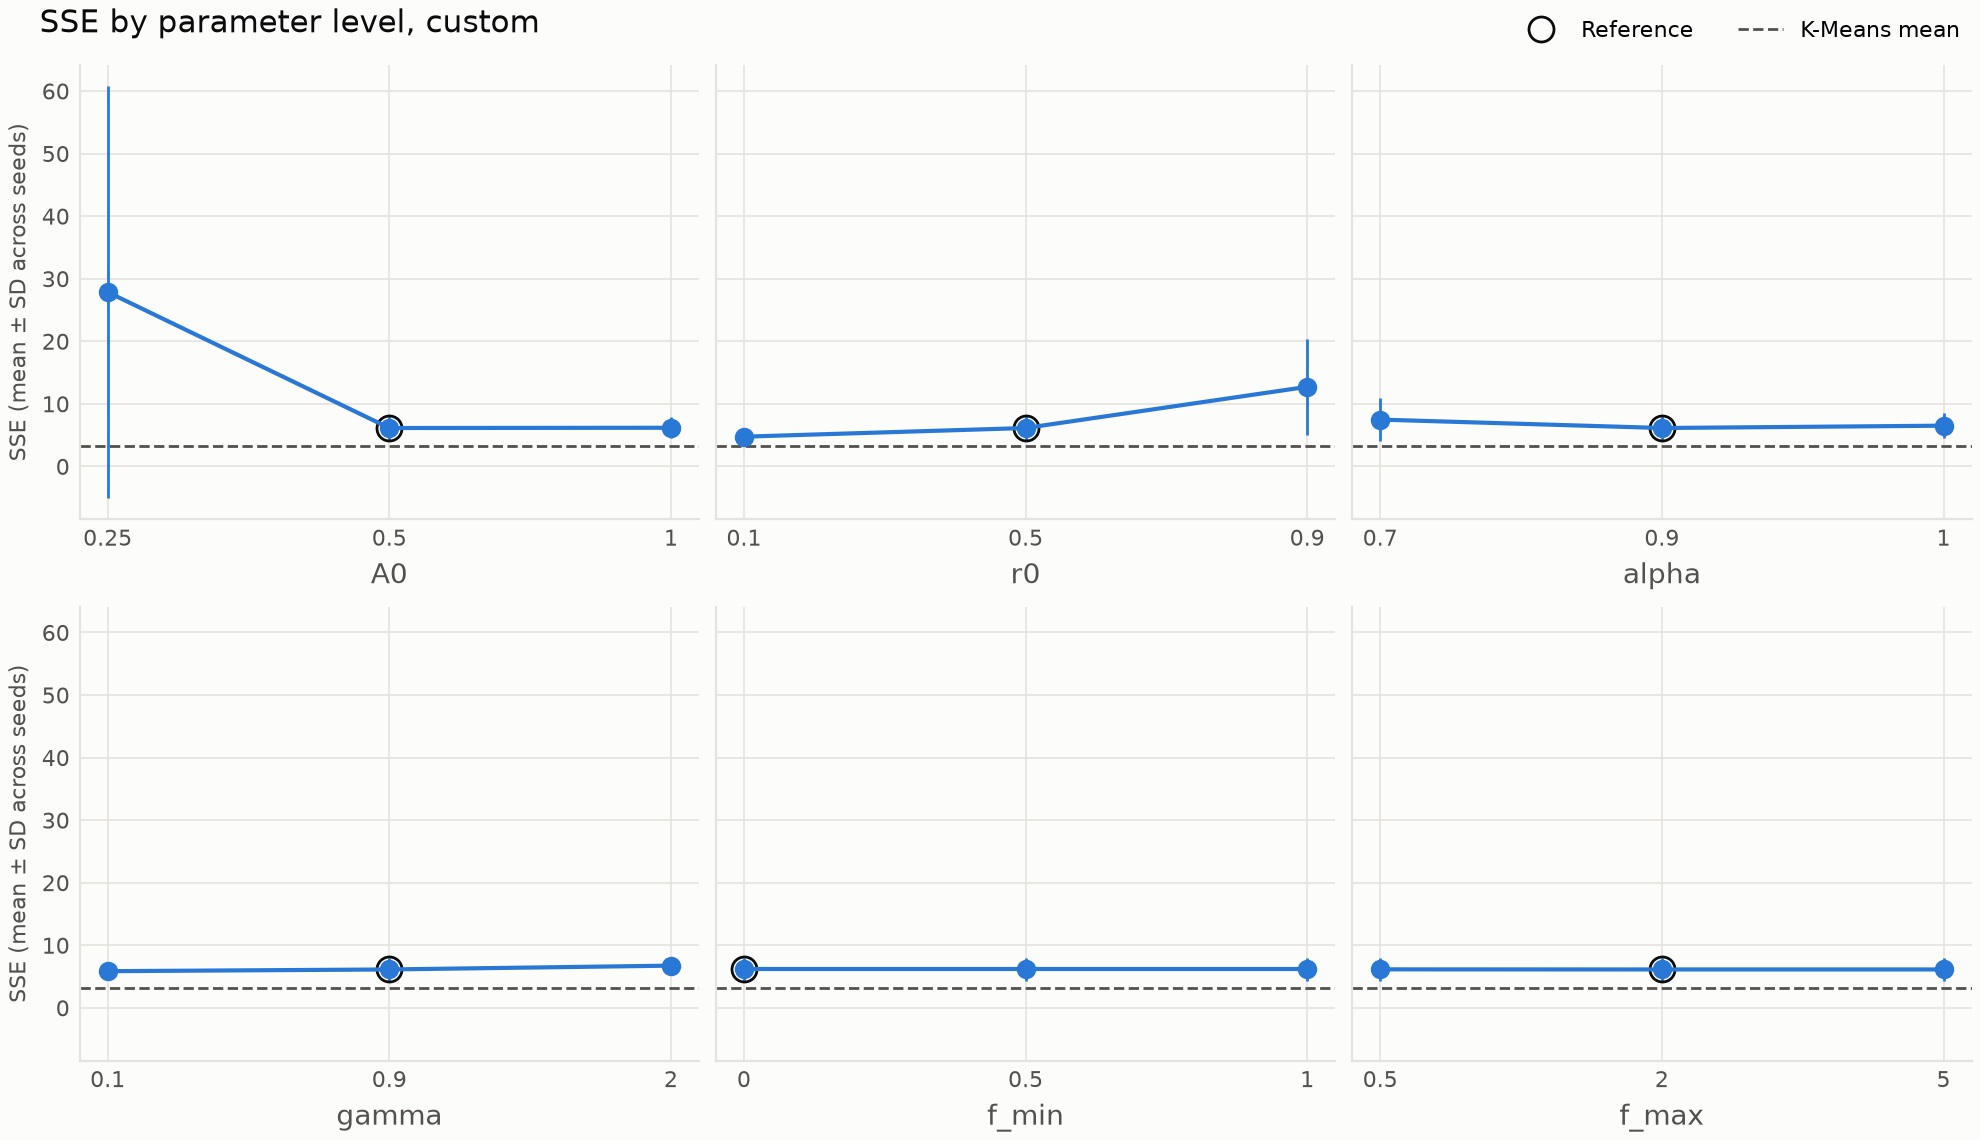

convergence_custom_A0.png


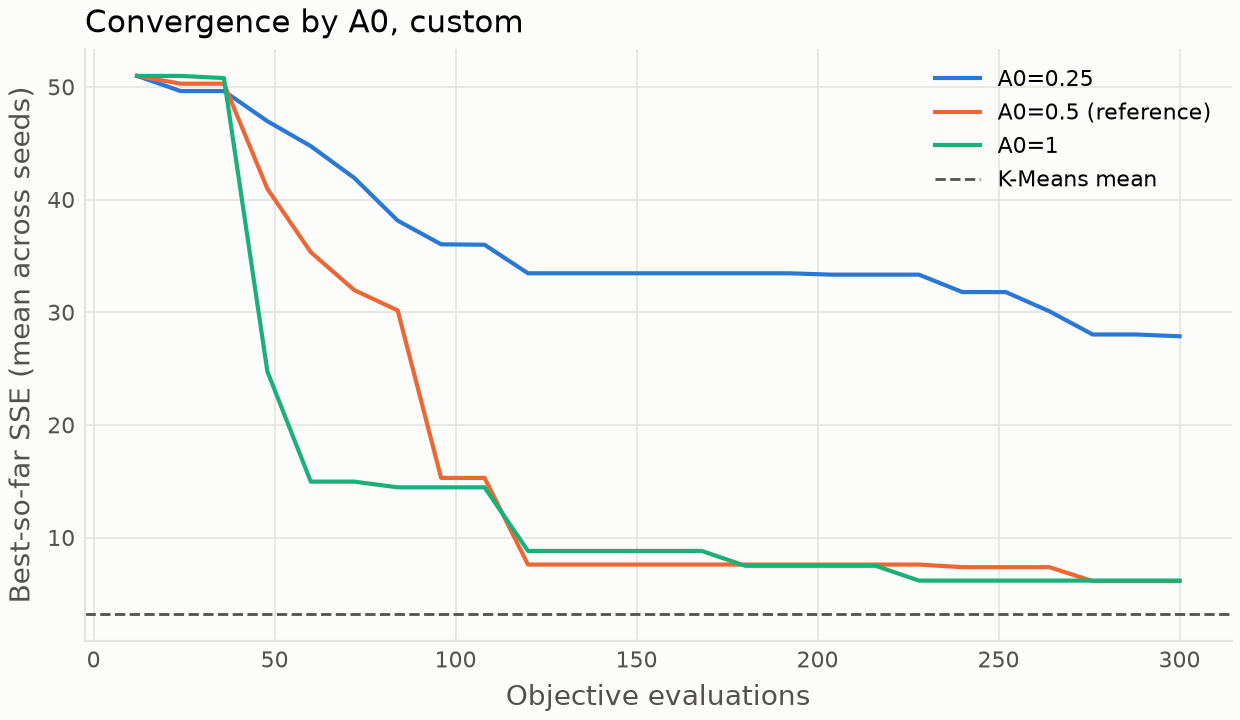

convergence_custom_r0.png


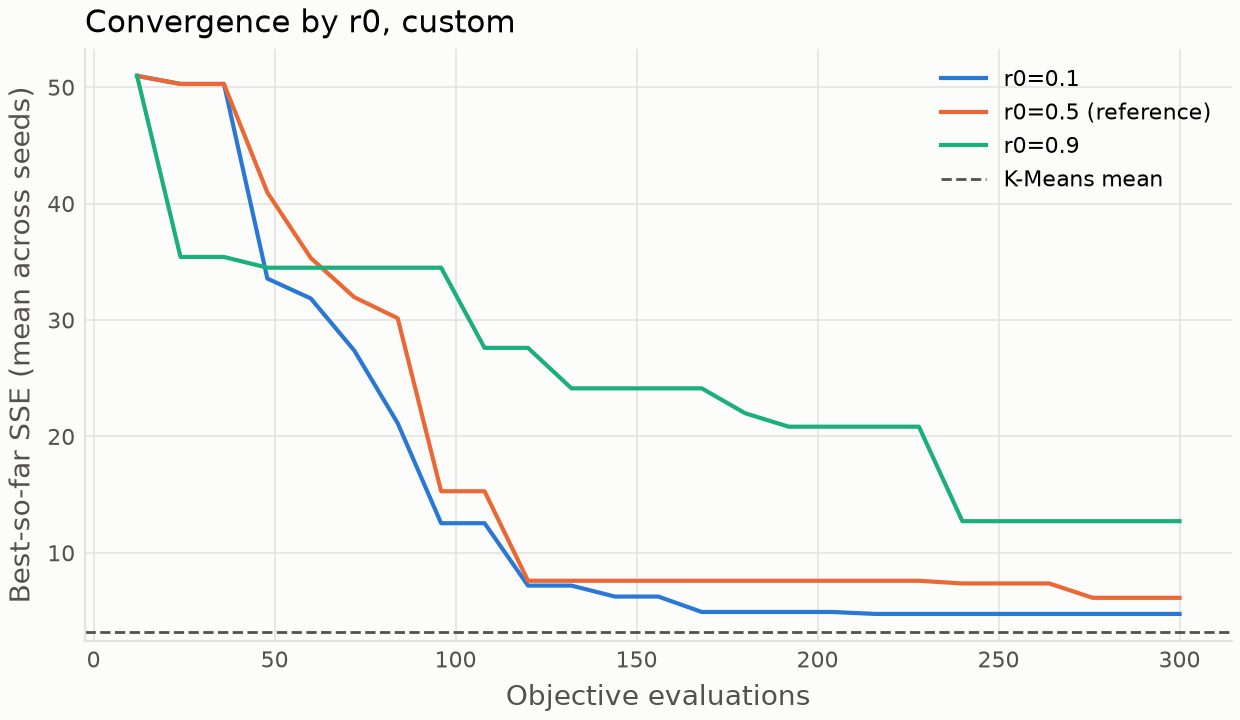

convergence_custom_alpha.png


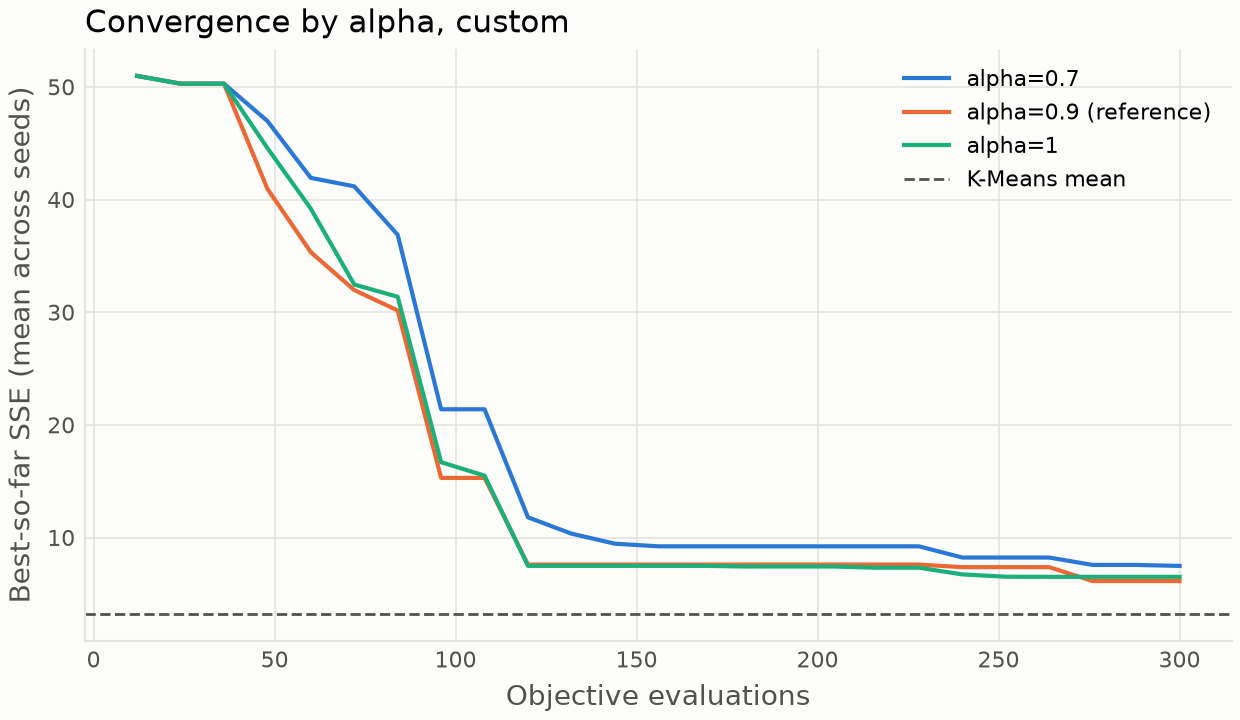

convergence_custom_gamma.png


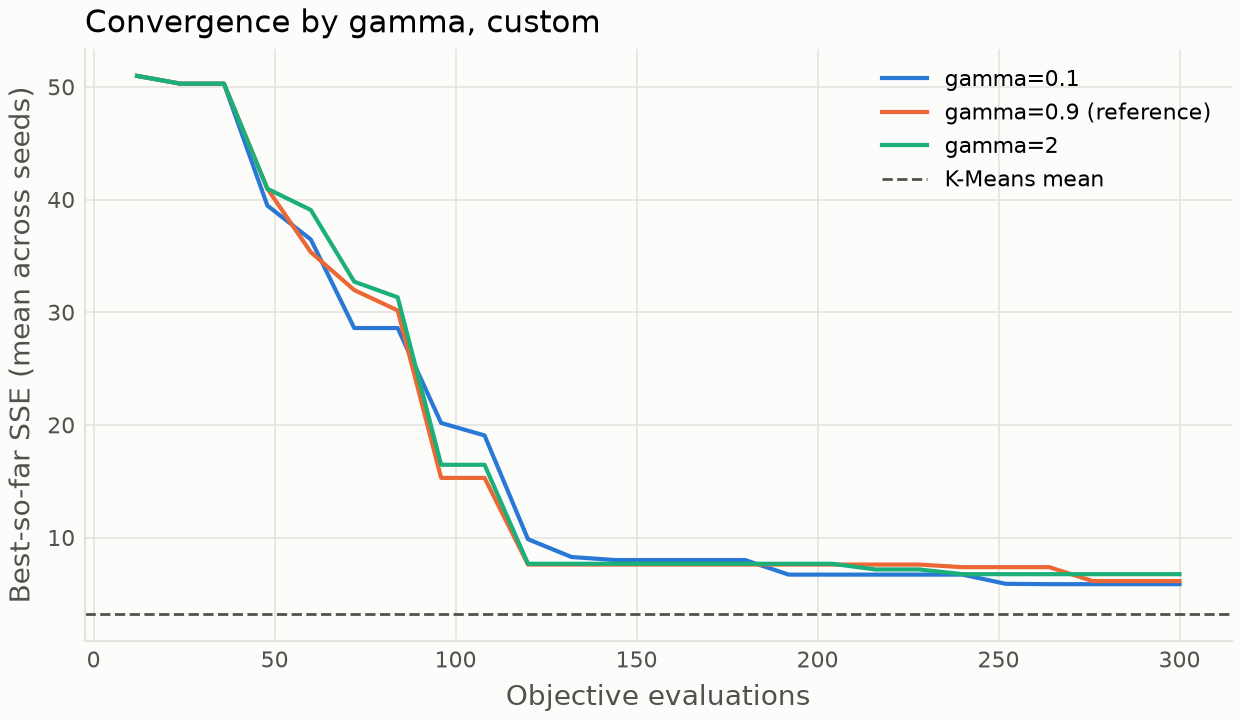

convergence_custom_f_min.png


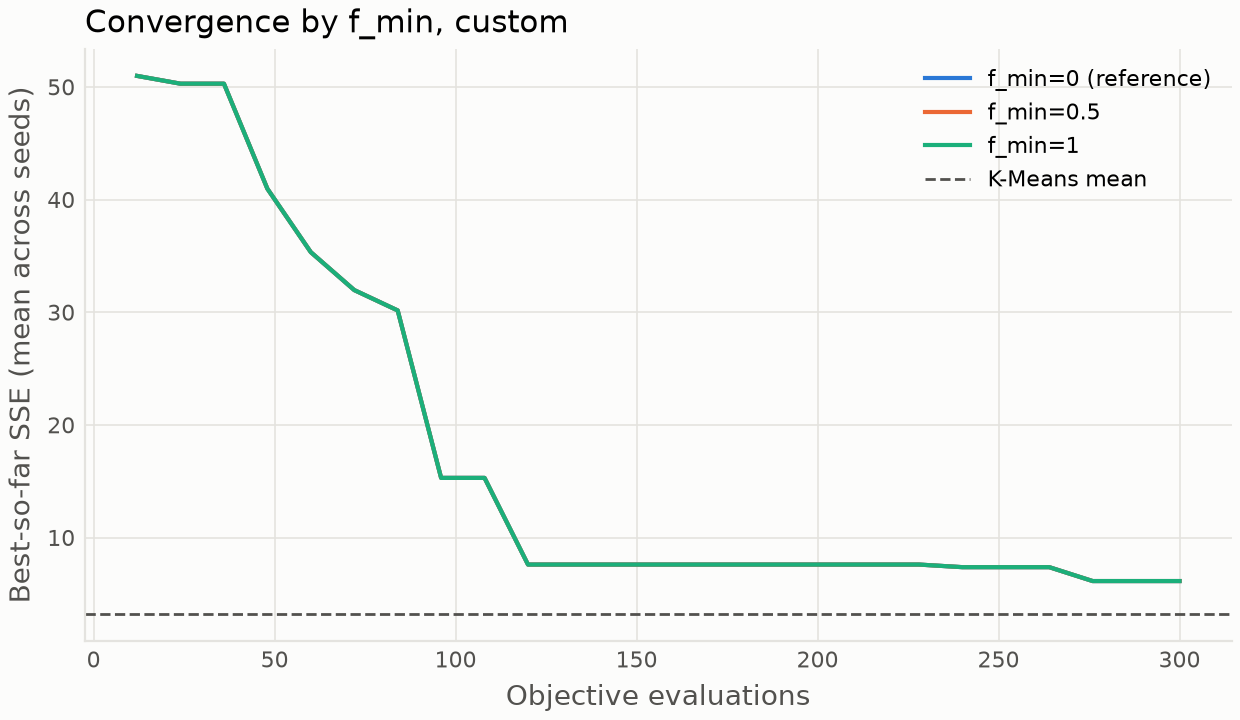

convergence_custom_f_max.png


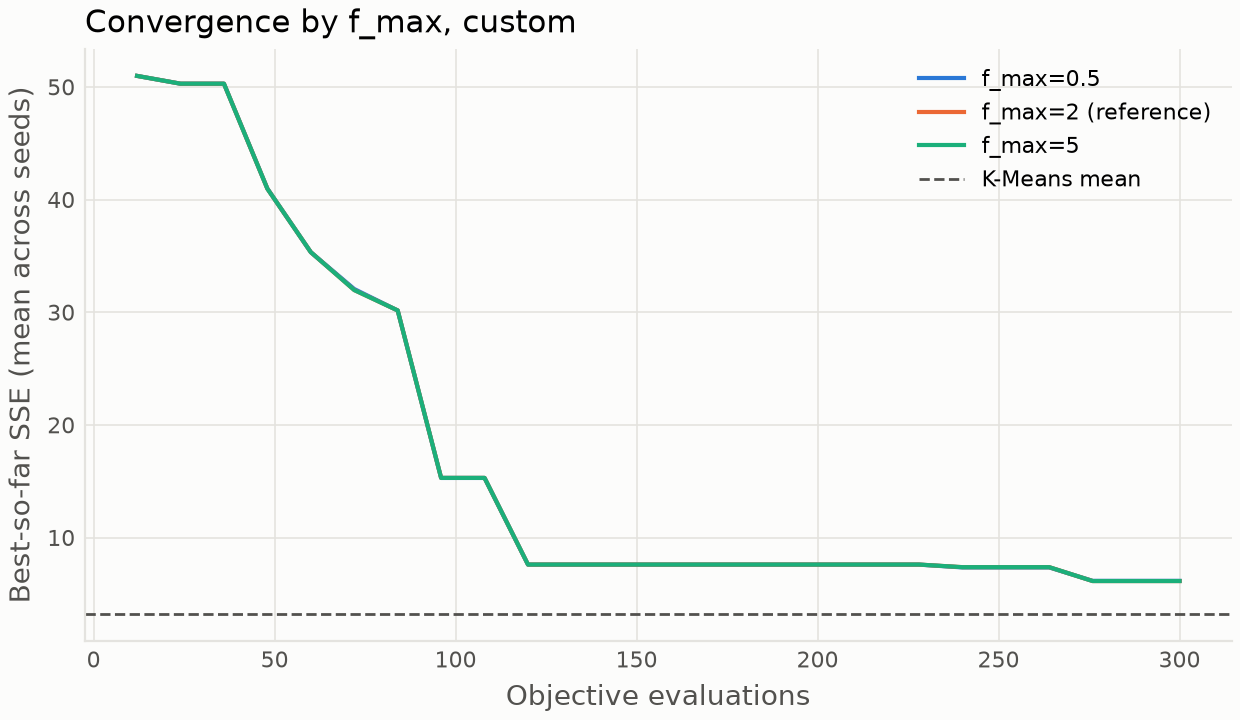

Grid: interaction_custom_A0_r0.png


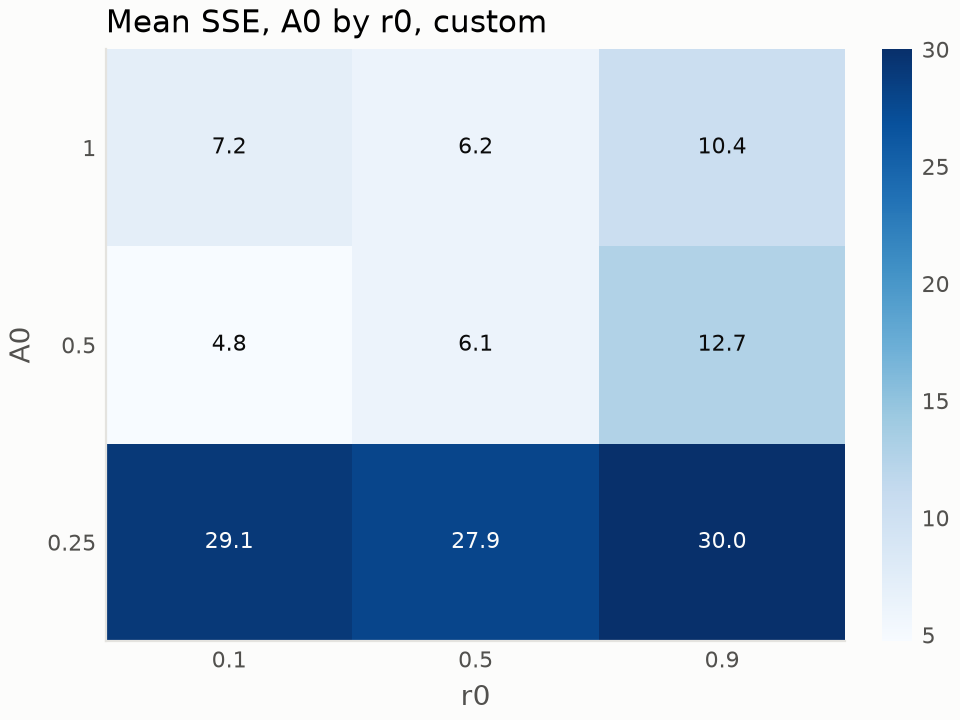

In [6]:
def show_png(figure_path):
    with Image.open(figure_path) as image:
        display(image.copy())

ofat_figures = generate_plots(ofat_outcome.directory)
for figure_path in ofat_figures:
    print(figure_path.name)
    show_png(figure_path)
if RUN_GRID:
    for figure_path in generate_plots(grid_outcome.directory):
        print("Grid:", figure_path.name)
        show_png(figure_path)

## 5. So sánh BA reference / K-Means và độ biến thiên

Hai seed chỉ là smoke check: SD/CI ước lượng rất yếu. Không lựa chọn tham số tối ưu từ
biểu đồ này. Runtime là thời gian fit; không gồm load/scale/metric/export. Báo cáo SSE,
Silhouette, cụm rỗng cùng nhau để tránh diễn giải một chỉ số đơn lẻ.

,dataset,algorithm,condition_id,metric,n_undefined,n,mean,std,median,q1,q3,minimum,maximum,ci95_low,ci95_high
72,custom,ba,reference,sse,0,2,6.135472,1.874820,6.135472,5.472623,6.798321,4.809774,7.461170,-10.709118,22.980062
73,custom,ba,reference,silhouette,0,2,0.879452,0.000000,0.879452,0.879452,0.879452,0.879452,0.879452,0.879452,0.879452
74,custom,ba,reference,runtime_seconds,0,2,0.007210,0.003984,0.007210,0.005802,0.008619,0.004393,0.010027,-0.028583,0.043004
78,custom,kmeans,kmeans,sse,0,2,3.217405,0.000000,3.217405,3.217405,3.217405,3.217405,3.217405,3.217405,3.217405
79,custom,kmeans,kmeans,silhouette,0,2,0.879452,0.000000,0.879452,0.879452,0.879452,0.879452,0.879452,0.879452,0.879452
80,custom,kmeans,kmeans,runtime_seconds,0,2,0.017407,0.015909,0.017407,0.011782,0.023032,0.006158,0.028656,-0.125527,0.160342


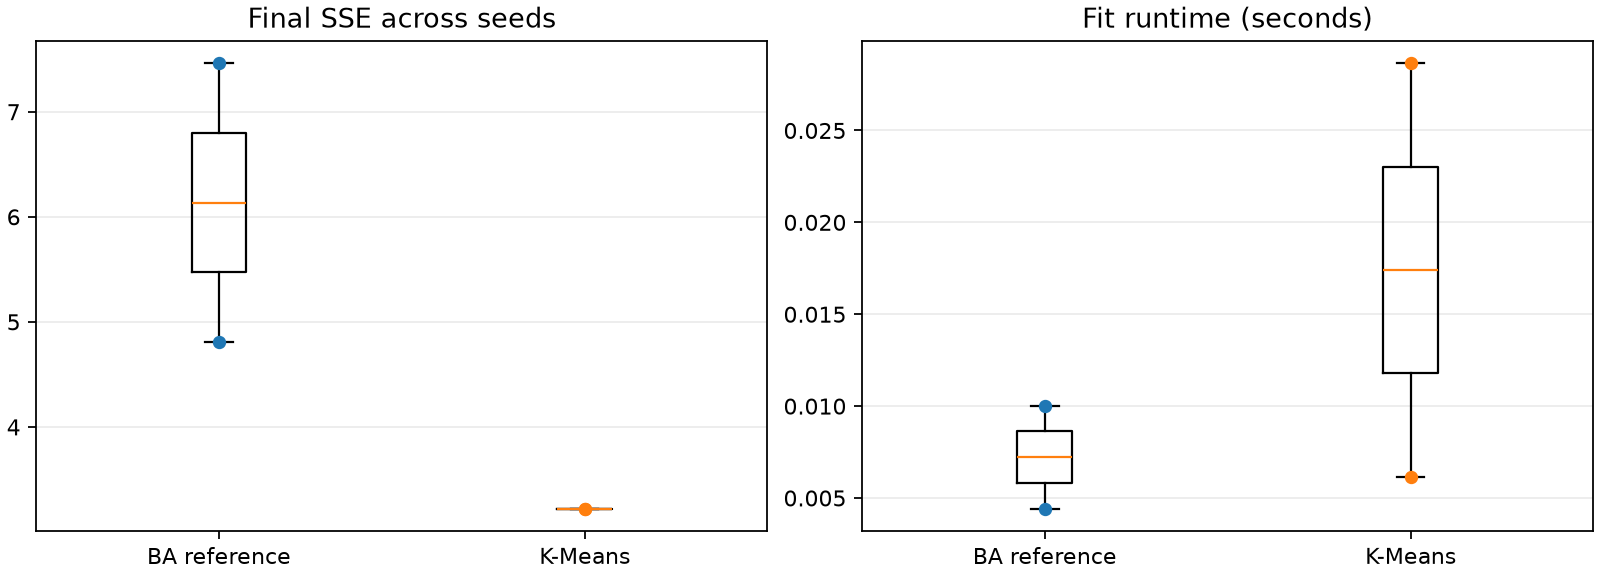

In [7]:
reference = frame[frame["condition_id"].isin(["reference", "kmeans"])].copy()
display(pd.read_csv(ofat_outcome.directory / "summary.csv").query(
    "condition_id in ['reference', 'kmeans'] and metric in ['sse', 'silhouette', 'runtime_seconds']"
))
figure_dir = SESSION_ROOT / "figures"
figure_dir.mkdir(exist_ok=True)
fig = Figure(figsize=(10, 3.6), layout="constrained")
axes = fig.subplots(1, 2)
for ax, metric, title in zip(axes, ["sse", "runtime_seconds"],
                            ["Final SSE across seeds", "Fit runtime (seconds)"], strict=True):
    groups = [reference.loc[reference.algorithm == a, metric].to_numpy() for a in ("ba", "kmeans")]
    ax.boxplot(groups, tick_labels=["BA reference", "K-Means"])
    for i, values in enumerate(groups, 1):
        ax.scatter(np.full(len(values), i), values, s=25, zorder=3)
    ax.set_title(title)
    ax.grid(axis="y", alpha=.25)
comparison_png = figure_dir / "baseline_variation.png"
fig.savefig(comparison_png, dpi=160)
show_png(comparison_png)

## 6. Bằng chứng về cơ chế global/local và ảnh hưởng tần số

Đếm candidate **được đánh giá**, không đếm global proposal đã bị local search thay thế.
Accepted global = tổng accepted − accepted local. Nếu nhiều sweep tần số bằng nhau,
kiểm tra tỷ lệ chấp nhận; không tự đổi dấu velocity để tạo hiệu ứng. Biểu đồ này ghi
nhận cơ chế thực tế, không thay cho phân tích nhân quả hay kiểm định xác nhận.

,n_global_candidates,n_local_candidates,n_accepted_global,n_accepted_local,global_accept_rate,local_accept_rate
condition_id,,,,,,
reference,280.0,296.0,3.0,71.0,0.010714,0.239865
A0=0.25,280.0,296.0,3.0,44.0,0.010714,0.148649
A0=1,281.0,295.0,8.0,95.0,0.028470,0.322034
r0=0.1,60.0,516.0,1.0,99.0,0.016667,0.191860
r0=0.9,486.0,90.0,13.0,26.0,0.026749,0.288889
alpha=0.7,280.0,296.0,3.0,58.0,0.010714,0.195946
alpha=1,281.0,295.0,4.0,82.0,0.014235,0.277966
gamma=0.1,187.0,389.0,3.0,91.0,0.016043,0.233933
gamma=2,286.0,290.0,4.0,79.0,0.013986,0.272414


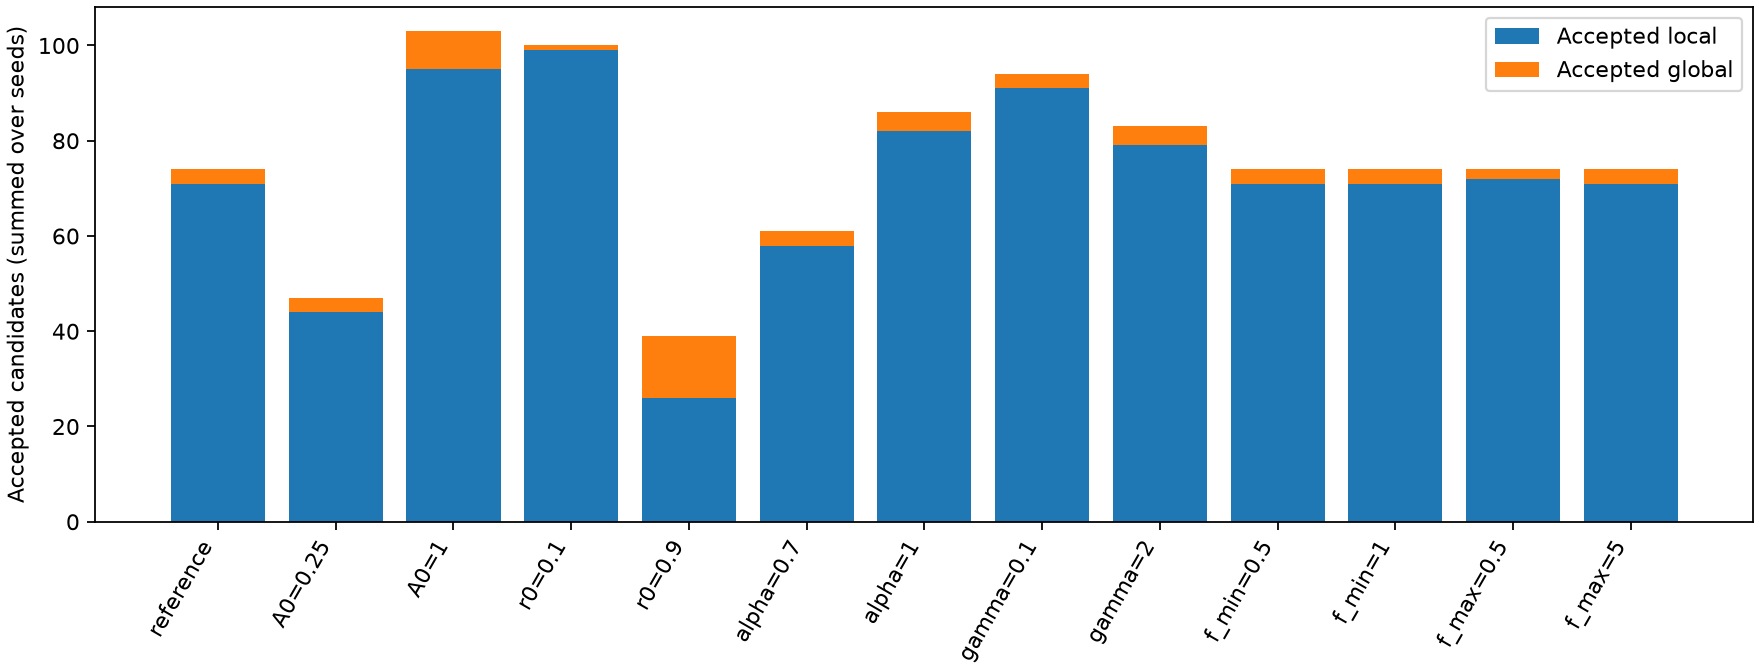

,dataset,condition_id,n,mean_difference,median_difference,n_a_lower,n_b_lower,n_tied,p_value,p_value_holm
0,custom,A0=0.25,2,21.726801,21.726801,1,1,0,1.0,1.0
1,custom,A0=1,2,0.040842,0.040842,1,1,0,1.0,1.0
2,custom,alpha=0.7,2,1.345329,1.345329,0,2,0,0.5,1.0
3,custom,alpha=1,2,0.373597,0.373597,1,1,0,1.0,1.0
4,custom,f_max=0.5,2,0.016646,0.016646,0,1,1,1.0,1.0
5,custom,f_max=5,2,0.000000,0.000000,0,0,2,1.0,1.0
6,custom,f_min=0.5,2,0.000000,0.000000,0,0,2,1.0,1.0
7,custom,f_min=1,2,0.000000,0.000000,0,0,2,1.0,1.0
8,custom,gamma=0.1,2,-0.276366,-0.276366,1,1,0,1.0,1.0
9,custom,gamma=2,2,0.610192,0.610192,0,1,1,1.0,1.0


Negative SSE difference favors listed condition; pilot/smoke p-values are exploratory.


In [8]:
ba = frame[frame.algorithm == "ba"].copy()
ba["n_global_candidates"] = POPULATION_SIZE * ba["n_iterations"] - ba["n_local_candidates"]
mechanism = ba.groupby("condition_id", sort=False)[[
    "n_global_candidates", "n_local_candidates", "n_accepted_global", "n_accepted_local"
]].sum()
mechanism["global_accept_rate"] = mechanism.n_accepted_global / mechanism.n_global_candidates.replace(0, np.nan)
mechanism["local_accept_rate"] = mechanism.n_accepted_local / mechanism.n_local_candidates.replace(0, np.nan)
display(mechanism)
fig = Figure(figsize=(11, 4.2), layout="constrained")
ax = fig.subplots()
x = np.arange(len(mechanism))
ax.bar(x, mechanism.n_accepted_local, label="Accepted local")
ax.bar(x, mechanism.n_accepted_global, bottom=mechanism.n_accepted_local, label="Accepted global")
ax.set_xticks(x, mechanism.index, rotation=60, ha="right")
ax.set_ylabel("Accepted candidates (summed over seeds)")
ax.legend()
mechanism_png = figure_dir / "acceptance_mechanism.png"
fig.savefig(mechanism_png, dpi=160)
show_png(mechanism_png)
paired = pd.read_csv(ofat_outcome.directory / "paired_vs_reference.csv")
display(paired)
print("Negative SSE difference favors listed condition; pilot/smoke p-values are exploratory.")

## 7. Kiểm tra nghiệm, tính lặp lại và hình cụm

Rerun BA reference ở seed đầu tiên; kiểm tra SSE tính lại từ centroid, trace lặp lại,
SSE best không tăng và centroid trong bounds. Chạy thêm K-Means cùng seed để vẽ hình.
Với D>2 hình chỉ dùng hai feature đầu, **không** phải không gian tối ưu đầy đủ.
Với D=1 dùng chỉ số mẫu trên trục ngang. Hình không chứng minh tìm được tối ưu toàn cục.

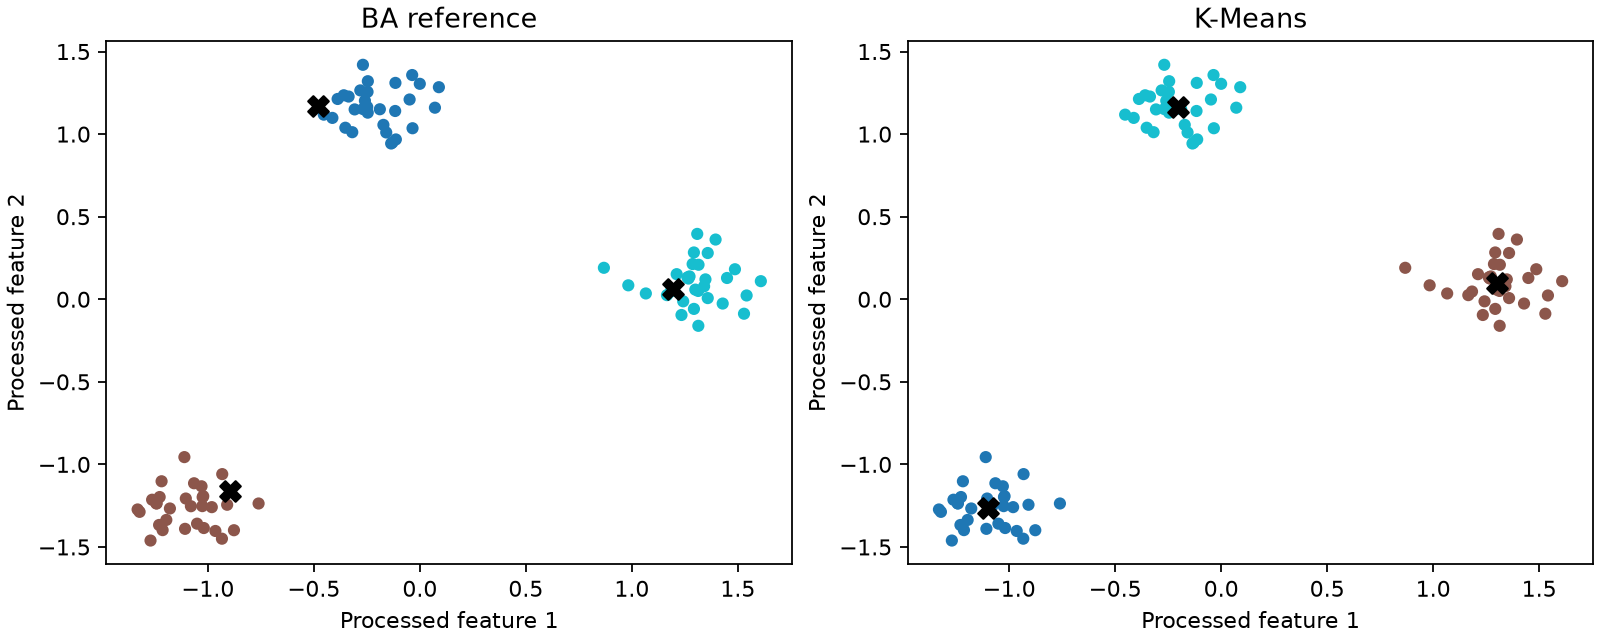

PASS: determinism, recomputed fitness, saved history, monotone best, finite/bounded centroids.


In [9]:
config = BAConfig.from_mapping({**ba_base, "n_clusters": N_CLUSTERS, "seed": SEEDS[0]})
model = BatClustering(config).fit(prepared.X)
again = BatClustering(config).fit(prepared.X)
assert model.history_.to_dict() == again.history_.to_dict()
assert model.best_fitness_ == compute_sse(prepared.X, model.centroids_)
assert np.all(np.diff(model.history_.best_fitness) <= 0)
assert np.isfinite(model.centroids_).all()
assert np.all(model.centroids_ >= model.bounds_.lower)
assert np.all(model.centroids_ <= model.bounds_.upper)
saved = next(r for r in ofat_records if r["condition_id"] == "reference" and r["seed"] == SEEDS[0])
assert model.best_fitness_ == saved["sse"]
assert model.history_.to_dict() == saved["history"]
km = run_kmeans(prepared.X, KMeansConfig(n_clusters=N_CLUSTERS, seed=SEEDS[0], **base["kmeans"]))
assert km.sse == compute_sse(prepared.X, km.centroids)
fig = Figure(figsize=(10, 4), layout="constrained")
axes = fig.subplots(1, 2)
for ax, labels, centers, title in zip(
    axes, [model.labels_, km.labels], [model.centroids_, km.centroids],
    ["BA reference", "K-Means"], strict=True,
):
    if prepared.X.shape[1] >= 2:
        ax.scatter(prepared.X[:, 0], prepared.X[:, 1], c=labels, cmap="tab10", s=20)
        ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=85)
        ax.set_xlabel("Processed feature 1")
        ax.set_ylabel("Processed feature 2")
    else:
        ax.scatter(np.arange(len(prepared.X)), prepared.X[:, 0], c=labels, cmap="tab10", s=20)
        for center in centers[:, 0]:
            ax.axhline(center, color="black", linestyle="--", alpha=.5)
        ax.set_xlabel("Sample index")
        ax.set_ylabel("Processed feature 1")
    ax.set_title(title)
clusters_png = figure_dir / "cluster_projection.png"
fig.savefig(clusters_png, dpi=160)
show_png(clusters_png)
print("PASS: determinism, recomputed fitness, saved history, monotone best, finite/bounded centroids.")

## 8. Hồ sơ bằng chứng và cách đọc kết quả

Mỗi phiên có settings, manifest/config/dataset hash, raw JSONL, CSV, summary, paired
comparisons và các PNG. Resume/overwrite không được dùng lên phiên cũ. Các assertion
chứng minh các điều kiện được kiểm tra trên dữ liệu/seed này, không chứng minh mọi input
đều đúng hay BA vượt K-Means. OFAT bỏ sót tương tác; grid chỉ minh họa một cặp. Chưa
chạy discovery/confirmation. Đọc `docs/EXPERIMENT_DESIGN.md` trước khi tăng quy mô.
Khi dùng CSV riêng: thay path/K/label ở đầu và Run All; không đọc output cũ như kết quả mới.

In [10]:
evidence = {
    "purpose": "engineering_smoke_not_confirmed_research",
    "dataset_path": str(path), "data_sha256": prepared.sha256,
    "ofat_records": len(ofat_records), "seeds": list(SEEDS),
    "toy_checks_passed": True, "reference_recomputation_passed": True,
    "determinism_passed": True, "historical_results_overwritten": False,
    "ofat_manifest": str(ofat_outcome.directory / "manifest.json"),
    "generated_pngs": [str(p) for p in sorted(SESSION_ROOT.rglob("*.png"))],
}
evidence_path = SESSION_ROOT / "notebook_evidence.json"
evidence_path.write_text(json.dumps(evidence, indent=2) + "\n")
print("Evidence:", evidence_path)
print("PNG count:", len(evidence["generated_pngs"]))
display(pd.DataFrame([{
    "dataset": path.name, "seeds": str(SEEDS), "OFAT records": len(ofat_records),
    "global accepted (OFAT)": int(ba.n_accepted_global.sum()),
    "local accepted (OFAT)": int(ba.n_accepted_local.sum()),
    "BA reference SSE mean": float(reference.loc[reference.algorithm == "ba", "sse"].mean()),
    "K-Means SSE mean": float(reference.loc[reference.algorithm == "kmeans", "sse"].mean()),
}]))

Evidence: /home/vxh/Desktop/New Folder/ba-clustering/results/notebook_20261105T105340Z_b4df6629/notebook_evidence.json
PNG count: 11


,dataset,seeds,OFAT records,global accepted (OFAT),local accepted (OFAT),BA reference SSE mean,K-Means SSE mean
0,example_blobs.csv,"(0, 1)",28,53,930,6.135472,3.217405
